# 🕸️ DeepGuard — Extra Module: Graph Neural Network (GNN) for laundering networks
**Optional advanced module.** The core DeepGuard detector is *Isolation Forest + Autoencoder + XGBoost + SHAP* (`DeepGuard_Training_Final.ipynb`). This notebook adds a **separate GNN** that looks at the *network of accounts* — who pays whom — which is the natural complement to your MongoDB `$graphLookup` + Cytoscape.js graph visualiser.

**It is saved completely separately** from the core models (`saved_models_gnn/`) and also exports two files for the app:
* `gnn_account_risk.csv` — a GNN risk score per account (colour the nodes of your Cytoscape graph)
* `cytoscape_top_alerts.json` — nodes + edges of the highest-risk transactions, ready for Cytoscape.js

**Corrections vs the old GNN notebook (all kept) + improvements in this version**

| Issue in the old notebook | Fix |
|---|---|
| Random split → laundering chains leak between train/test | **time-based 60/20/20 split**, identical to the rest of DeepGuard |
| One graph with train+val+test edges used for training | **three temporal graphs**: train = train edges · validation = train+val · test = all. Val/test **labels never used** |
| Sum aggregation + BatchNorm (graph grows over time) | **mean aggregation + LayerNorm** |
| Hard-coded "XGBoost 0.62 / 0.58" | XGBoost reference **trained here** on the same features and split |
| Only ROC / AP / F1 | **full metric set**, classification reports, bootstrap CI, paired test, figures, zip |
| **NEW** under-training (only 150 full-graph steps, constant LR) | up to **250 steps with cosine LR decay**, patience 8 evaluations |
| **NEW** threshold may drift as the graph grows | **score-shift check** + a label-free **rank-matched threshold** variant |
| **NEW** model not reusable | weights + config + scaler + account map + a tested `gnn_model_def.py` saved in its own folder, with a **reload test** |

**GNN design (Multi-GNN ideas, Egressy et al.):** reverse message passing with a direction flag · port numbering (`Pair_n`) · GINE-style edge-aware layers · edge-classification head on `[h_sender, h_receiver, edge embedding]`.

**Models compared on the same untouched test period:** `XGBoost (reference)` · `GNN (edge features only)` · `GNN + behavioural features` · `Blend (XGBoost + best GNN)`

> ✅ **Status:** the code path was executed end-to-end in a sandbox on synthetic data (QUICK_TEST) and all outputs were produced. It has **not** been run on the real 5M-row file — set `QUICK_TEST = True` first (≈ 2 min), then `False`. Quote only numbers this notebook prints for you.
>
> ⚠️ **Scoring mode (state this in your report):** a GNN scores a *batch/period* using the whole period graph (structure + features, **never labels**), so a test transaction's neighbourhood may include later test-period transactions. XGBoost features are strictly past-only (streaming). So the GNN is a **periodic network-analysis / investigation module**, not the real-time scorer.
>
> Runtime: High-RAM + T4 GPU ≈ 40–60 min for the full run. Out of memory → set `HIDDEN = 32`.

In [ ]:
import os, time, json, joblib, shutil, warnings, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
!pip install -q xgboost
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve, precision_recall_curve, f1_score, fbeta_score,
                             precision_score, recall_score, accuracy_score, balanced_accuracy_score, matthews_corrcoef,
                             cohen_kappa_score, brier_score_loss, log_loss, classification_report, confusion_matrix)
import xgboost as xgb, torch, torch.nn as nn, torch.nn.functional as F_
from torch.utils.checkpoint import checkpoint

QUICK_TEST = False        # 🔧 True = first 600k rows, few epochs: a 2-minute check that the code runs. Set False for the real run.
ROOT = '/content'; OUT = f'{ROOT}/deepguard_gnn_results'; FIG, TAB, MOD = f'{OUT}/figures', f'{OUT}/tables', f'{OUT}/models'
for d in (FIG, TAB, MOD): os.makedirs(d, exist_ok=True)
SAVED = []
XGB_DEVICE = 'cuda' if shutil.which('nvidia-smi') else 'cpu'
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED = 42; np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams.update({'figure.facecolor':'white','axes.facecolor':'white','axes.grid':True,'grid.alpha':.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10,'axes.titleweight':'bold'})
def save_fig(name):
    plt.tight_layout(); p = f'{FIG}/{name}.png'; plt.savefig(p, dpi=160, bbox_inches='tight', facecolor='white'); SAVED.append(p); plt.show()
def save_table(df_, name, index=True):
    p = f'{TAB}/{name}.csv'; df_.to_csv(p, index=index); SAVED.append(p)
print("XGBoost", xgb.__version__, "| torch", torch.__version__, "| device:", DEV, "| QUICK_TEST =", QUICK_TEST)
if DEV.type == 'cpu': print("⚠️ No GPU: switch to Runtime → T4 GPU, otherwise this will be extremely slow.")

XGBoost 3.4.1 | torch 2.11.0+cu130 | device: cuda | QUICK_TEST = False


## 📥 Step 1 — Load the FULL HI-Small file (time-sorted)

In [ ]:
DATA_PATH = '/content/data/HI-Small_Trans.csv'
ALT_PATH  = '/content/drive/MyDrive/fyp-projects/final_model/HI-Small_Trans.csv'   # 🔧 your Drive copy, if you have one
if not os.path.exists(DATA_PATH) and os.path.exists(ALT_PATH): DATA_PATH = ALT_PATH
if not os.path.exists(DATA_PATH):
    os.makedirs('/content/data', exist_ok=True)
    if not os.path.exists('/root/.kaggle/kaggle.json'):
        from google.colab import files
        up = files.upload(); os.makedirs('/root/.kaggle', exist_ok=True)
        open('/root/.kaggle/kaggle.json','wb').write(up['kaggle.json']); os.chmod('/root/.kaggle/kaggle.json', 0o600)
    !kaggle datasets download -d ealtman2019/ibm-transactions-for-anti-money-laundering-aml -f HI-Small_Trans.csv -p /content/data
    if os.path.exists('/content/data/HI-Small_Trans.csv.zip'):
        !unzip -o /content/data/HI-Small_Trans.csv.zip -d /content/data
    DATA_PATH = '/content/data/HI-Small_Trans.csv'

names = ['Timestamp','From_Bank','Sender','To_Bank','Receiver','Amount_Received','Receiving_Currency',
         'Amount_Paid','Payment_Currency','Payment_Format','Is_Laundering']
df = pd.read_csv(DATA_PATH, header=0, names=names,
                 dtype={'From_Bank':'int32','To_Bank':'int32','Amount_Received':'float64','Amount_Paid':'float64','Is_Laundering':'int8'})
df['Timestamp'] = pd.to_datetime(df['Timestamp'], format='%Y/%m/%d %H:%M')
if not QUICK_TEST: assert len(df) > 5_000_000, f"File incomplete: {len(df):,} rows"
df = df.sort_values('Timestamp', kind='stable').reset_index(drop=True)
if QUICK_TEST: df = df.iloc[:600_000].reset_index(drop=True)
y_all = df['Is_Laundering'].to_numpy()
print(f"{len(df):,} rows | fraud {int(y_all.sum()):,} ({y_all.mean()*100:.3f}%)")

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml
License(s): Community Data License Agreement - Sharing - Version 1.0
100% 454M/454M [00:29<00:00, 16.0MB/s]

5,078,345 rows | fraud 5,177 (0.102%)


## ⚙️ Step 2 — Past-only edge features (same verified code as Notebook 4) + graph arrays

In [ ]:
import numpy as np, pandas as pd

def build_features(df):
    """df must be sorted by time (stable). Columns: Timestamp, From_Bank, Sender, To_Bank, Receiver,
    Amount_Received, Receiving_Currency, Amount_Paid, Payment_Currency, Payment_Format.
    EVERY feature uses only rows that come EARLIER in the sorted order (plus the row itself) -> no future leakage,
    and train/val/test rows get features computed in exactly the same way."""
    n = len(df)
    allacc = pd.concat([df['Sender'], df['Receiver']], ignore_index=True)
    codes, _ = pd.factorize(allacc)
    sid = codes[:n].astype('int64'); rid = codes[n:].astype('int64')
    t = (df['Timestamp'] - df['Timestamp'].min()).dt.total_seconds().to_numpy()
    ap = df['Amount_Paid'].to_numpy('float64'); ar = df['Amount_Received'].to_numpy('float64')

    w = pd.DataFrame({'sid': sid, 'rid': rid, 't': t, 'ap': ap, 'ar': ar})
    w['hb'] = (t // 3600).astype('int64'); w['db'] = (t // 86400).astype('int64')
    F = pd.DataFrame(index=w.index)

    # ---- basic row features ----
    F['Log_Amount_Paid']  = np.log1p(ap)
    F['Log_Amount_Recv']  = np.log1p(ar)
    F['Log_Amount_Ratio'] = F['Log_Amount_Paid'] - F['Log_Amount_Recv']
    F['Is_Round_Amount']  = ((ap % 1000) == 0).astype('int8')
    hour = df['Timestamp'].dt.hour.to_numpy()
    F['Hour'] = hour; F['DayOfWeek'] = df['Timestamp'].dt.dayofweek.to_numpy()
    F['Is_Night'] = ((hour >= 22) | (hour <= 5)).astype('int8')
    F['Is_Self_Transfer']  = (sid == rid).astype('int8')
    F['Is_Cross_Bank']     = (df['From_Bank'].to_numpy() != df['To_Bank'].to_numpy()).astype('int8')
    F['Is_Cross_Currency'] = (df['Receiving_Currency'].astype(str).to_numpy() != df['Payment_Currency'].astype(str).to_numpy()).astype('int8')
    for col, name in [('Payment_Format','Payment_Format_enc'), ('Payment_Currency','Payment_Currency_enc'), ('Receiving_Currency','Receiving_Currency_enc')]:
        F[name] = pd.factorize(df[col].astype(str), sort=True)[0].astype('int8')

    # ---- sender history (strictly earlier rows) ----
    gs = w.groupby('sid')
    F['S_out_n']     = gs.cumcount()
    prev_sum         = gs['ap'].cumsum() - w['ap']
    avg_prev         = prev_sum / F['S_out_n'].where(F['S_out_n'] > 0)
    F['S_amt_vs_avg'] = F['Log_Amount_Paid'] - np.log1p(avg_prev)          # NaN if no history
    F['S_dt_prev']   = gs['t'].diff()                                      # seconds since sender's last tx
    pair_n           = w.groupby(['sid', 'rid']).cumcount()
    F['Pair_n']      = pair_n                                              # times this exact pair transacted before
    new_pair         = (pair_n == 0).astype('int64')
    F['S_uniq_recv'] = new_pair.groupby(w['sid']).cumsum() - new_pair      # distinct receivers BEFORE this row
    F['S_new_recv_rate'] = F['S_uniq_recv'] / (F['S_out_n'] + 1)
    F['S_same_hour'] = w.groupby(['sid', 'hb']).cumcount()
    F['S_same_day']  = w.groupby(['sid', 'db']).cumcount()
    F['S_same_amt']  = w.groupby(['sid', 'ap']).cumcount()                 # repeated identical amounts (structuring)

    # ---- receiver history ----
    gr = w.groupby('rid')
    F['R_in_n']      = gr.cumcount()
    F['R_dt_prev']   = gr['t'].diff()
    F['R_uniq_send'] = new_pair.groupby(w['rid']).cumsum() - new_pair
    F['R_same_hour'] = w.groupby(['rid', 'hb']).cumcount()
    F['R_same_day']  = w.groupby(['rid', 'db']).cumcount()
    r_prev_sum       = gr['ar'].cumsum() - w['ar']
    F['R_amt_vs_avg'] = F['Log_Amount_Recv'] - np.log1p(r_prev_sum / F['R_in_n'].where(F['R_in_n'] > 0))

    # ---- in/out behaviour of each account (pass-through / mule patterns) ----
    ev_acct = np.concatenate([sid, rid]); ev_pos = np.arange(2 * n)
    ev_ord  = np.concatenate([np.arange(n), np.arange(n)])
    ev_in   = np.concatenate([np.zeros(n, 'int8'), np.ones(n, 'int8')])
    ev_amt  = np.concatenate([ap, ar])
    order   = np.lexsort((ev_in, ev_ord))                                  # time order; out-event before in-event of the same row
    E = pd.DataFrame({'a': ev_acct[order], 'isin': ev_in[order].astype('int64'), 'amt': ev_amt[order], 'pos': ev_pos[order]})
    E['in_amt']  = E['amt'] * E['isin']
    E['out_amt'] = E['amt'] * (1 - E['isin'])
    E['isout']   = 1 - E['isin']
    ge = E.groupby('a')
    cum_in_amt  = ge['in_amt'].cumsum()  - E['in_amt']
    cum_out_amt = ge['out_amt'].cumsum() - E['out_amt']
    cum_in_n    = ge['isin'].cumsum()    - E['isin']
    cum_out_n   = ge['isout'].cumsum()   - E['isout']
    res = np.zeros((4, 2 * n))
    res[0, E['pos'].to_numpy()] = cum_in_amt.to_numpy()
    res[1, E['pos'].to_numpy()] = cum_out_amt.to_numpy()
    res[2, E['pos'].to_numpy()] = cum_in_n.to_numpy()
    res[3, E['pos'].to_numpy()] = cum_out_n.to_numpy()
    F['S_prior_in_n']     = res[2, :n]
    F['S_prior_in_amt']   = np.log1p(res[0, :n])
    F['S_passthru']       = F['Log_Amount_Paid'] - F['S_prior_in_amt']     # sending more than it ever received?
    selfm = (sid == rid)                                                   # same-row out event must not count as "prior" for the receiver
    F['R_prior_out_n']    = res[3, n:] - selfm
    F['R_prior_out_amt']  = np.log1p(np.maximum(res[1, n:] - ap * selfm, 0))
    F['R_prior_in_amt']   = np.log1p(res[0, n:])
    F['R_out_in_ratio']   = F['R_prior_out_amt'] - F['R_prior_in_amt']

    F = F.astype('float32')
    return F

In [ ]:
def window_features(df):
    """Past-only time-window activity. Own-role windows use position order (same as cumcount);
    cross-role windows (sender's recent INCOMING, receiver's recent OUTGOING) use strictly earlier timestamps."""
    n = len(df)
    allacc = pd.concat([df['Sender'], df['Receiver']], ignore_index=True)
    codes, _ = pd.factorize(allacc)
    sid = codes[:n].astype('int64'); rid = codes[n:].astype('int64')
    t = (df['Timestamp'] - df['Timestamp'].min()).dt.total_seconds().to_numpy().astype('int64')
    ap = df['Amount_Paid'].to_numpy('float64'); ar = df['Amount_Received'].to_numpy('float64')
    K = np.int64(10**8)
    out = {}
    def own(acct, amt, tag):
        order = np.lexsort((np.arange(n), t, acct))
        key = acct[order] * K + t[order]
        cs = np.concatenate([[0.0], np.cumsum(amt[order])])
        pos = np.arange(n)
        for W, nm in [(3600, '1h'), (86400, '24h')]:
            lo = np.searchsorted(key, key - W, side='left')
            c = np.empty(n); c[order] = pos - lo
            out[f'{tag}_cnt_{nm}'] = c
            if nm == '24h':
                a = np.empty(n); a[order] = cs[pos] - cs[lo]
                out[f'{tag}_amt_24h'] = np.log1p(np.maximum(a, 0))
    def cross(ev_acct, ev_amt, q_acct, tag):
        order = np.lexsort((t, ev_acct))
        ek = ev_acct[order] * K + t[order]
        cs = np.concatenate([[0.0], np.cumsum(ev_amt[order])])
        qk = q_acct * K + t
        hi = np.searchsorted(ek, qk, side='left')           # events with strictly earlier timestamp
        for W, nm in [(3600, '1h'), (86400, '24h')]:
            lo = np.searchsorted(ek, qk - W, side='left')
            out[f'{tag}_cnt_{nm}'] = (hi - lo).astype('float64')
            if nm == '24h':
                out[f'{tag}_amt_24h'] = np.log1p(np.maximum(cs[hi] - cs[lo], 0))
    own(sid, ap, 'S_out'); own(rid, ar, 'R_in')
    cross(rid, ar, sid, 'S_in')      # money the SENDER received recently
    cross(sid, ap, rid, 'R_out')     # money the RECEIVER sent recently
    return pd.DataFrame(out).astype('float32')

In [ ]:
t0 = time.time()
Fdf = pd.concat([build_features(df), window_features(df)], axis=1)
feature_cols = list(Fdf.columns)
n = len(y_all); i_tr, i_va = int(n*0.6), int(n*0.8)
ymin_ok = 20 if QUICK_TEST else 200
y_tr, y_va, y_te = y_all[:i_tr], y_all[i_tr:i_va], y_all[i_va:]
assert y_va.sum() >= ymin_ok and y_te.sum() >= ymin_ok, "too few positives in val/test"
split_tbl = pd.DataFrame({'Rows':[len(y_tr),len(y_va),len(y_te)], 'Fraud':[int(y_tr.sum()),int(y_va.sum()),int(y_te.sum())],
                          'Fraud_%':[y_tr.mean()*100,y_va.mean()*100,y_te.mean()*100]}, index=['Train (60%)','Validation (20%)','Test (20%)'])
display(split_tbl.round(4)); save_table(split_tbl, 'G00_data_split')

# ---- node ids (accounts) and edge endpoints ----
codes, ACC_UNIQ = pd.factorize(pd.concat([df['Sender'], df['Receiver']], ignore_index=True)); ACC_UNIQ = np.asarray(ACC_UNIQ).astype(str)
src_np, dst_np = codes[:n].astype('int64'), codes[n:].astype('int64'); N_NODES = int(codes.max()) + 1
print(f"{N_NODES:,} accounts (nodes) | {n:,} transactions (edges) | features: {len(feature_cols)} | built in {time.time()-t0:.0f}s")

# ---- reference table for XGBoost: raw 47 features ----
X_raw = Fdf.to_numpy(dtype='float32')

# ---- GNN edge-feature matrices (scalers fitted on TRAIN rows only) ----
cat_cols = ['Payment_Format_enc', 'Payment_Currency_enc', 'Receiving_Currency_enc']
num_cols = [c for c in feature_cols if c not in cat_cols]
BASIC = ['Log_Amount_Paid','Log_Amount_Recv','Log_Amount_Ratio','Is_Round_Amount','Hour','DayOfWeek','Is_Night',
         'Is_Self_Transfer','Is_Cross_Bank','Is_Cross_Currency','Pair_n']            # Pair_n = port number
def slog(X): return np.sign(X) * np.log1p(np.abs(X))
def fit_edge_scaler(Xnum_train):
    Z = slog(Xnum_train); med = np.nanmedian(Z, axis=0).astype('float32'); Z = np.where(np.isnan(Z), med, Z)
    mu = Z.mean(0).astype('float32'); sd = Z.std(0).astype('float32'); sd[sd < 1e-6] = 1.0
    return med, mu, sd
def apply_edge_scaler(X, med, mu, sd):
    Z = slog(X); Z = np.where(np.isnan(Z), med, Z); return np.clip((Z - mu) / sd, -6, 6).astype('float32')
def one_hot(v, k):
    a = np.zeros((len(v), k), 'float32'); a[np.arange(len(v)), v.astype(int)] = 1; return a

Xnum = Fdf[num_cols].to_numpy(dtype='float32')
E_MED, E_MU, E_SD = fit_edge_scaler(Xnum[:i_tr])
Xnum_s = apply_edge_scaler(Xnum, E_MED, E_MU, E_SD)
OH_DIMS = [int(Fdf[c].max()) + 1 for c in cat_cols]
OH = np.hstack([one_hot(Fdf[c].to_numpy(), k) for c, k in zip(cat_cols, OH_DIMS)])
bidx = [num_cols.index(c) for c in BASIC]
XE_A = np.hstack([Xnum_s[:, bidx], OH]).astype('float32')     # variant A: transaction features + port number only
XE_B = np.hstack([Xnum_s, OH]).astype('float32')              # variant B: + all behavioural / time-window features
print("edge-feature dims:  A =", XE_A.shape[1], " B =", XE_B.shape[1])
TX = df[['Timestamp','Sender','Receiver','Amount_Paid','Payment_Currency','Payment_Format']].iloc[i_va:].reset_index(drop=True)   # test-period rows, for the app export
del Fdf, Xnum, Xnum_s, df

,Rows,Fraud,Fraud_%
Train (60%),3047007,2298,0.0754
Validation (20%),1015669,1082,0.1065
Test (20%),1015669,1797,0.1769


515,080 accounts (nodes) | 5,078,345 transactions (edges) | features: 47 | built in 43s
edge-feature dims:  A = 48  B = 81


## 🧠 Step 3 — The GNN
* **Reverse message passing:** every edge is used in both directions; a learned *direction flag* tells the model which is the real one.
* **Port numbering:** `Pair_n` (repeats between the same pair) is an edge feature.
* **Edge-aware layers (GINE-style):** `message = ReLU(h_neighbour + W·edge_embedding)`; **mean** over incoming messages; MLP; residual; LayerNorm.
* **Edge head:** `[h_sender, h_receiver, edge embedding] → risk score`.
* **Three temporal graphs:** train = edges of the train period only · validation = train+val edges · test = all edges.
* Memory: layers are gradient-checkpointed and processed in chunks so the full graph fits a T4. If you still hit out-of-memory, set `HIDDEN = 32`.

In [ ]:
HIDDEN, LAYERS, DROP, LR = 48, 3, 0.1, 2e-3
EPOCHS      = 6 if QUICK_TEST else 250
EVAL_EVERY  = 2 if QUICK_TEST else 10
PATIENCE    = 3 if QUICK_TEST else 8          # in evaluations
NEG_PER_EPOCH = 100_000 if QUICK_TEST else 400_000
POS_W       = 20.0
CHUNK       = 1_500_000

class Net(nn.Module):
    def __init__(s, d_in, n_nodes, hid=HIDDEN, L=LAYERS, drop=DROP):
        super().__init__()
        s.N, s.L, s.drop = n_nodes, L, drop
        s.edge_proj = nn.Linear(d_in, hid); s.flag = nn.Parameter(torch.zeros(2, hid)); s.node0 = nn.Parameter(torch.randn(hid) * 0.1)
        s.lin_e = nn.ModuleList([nn.Linear(hid, hid) for _ in range(L)])
        s.mlps  = nn.ModuleList([nn.Sequential(nn.Linear(hid, hid), nn.ReLU(), nn.Linear(hid, hid)) for _ in range(L)])
        s.norms = nn.ModuleList([nn.LayerNorm(hid) for _ in range(L)])
        s.eps   = nn.Parameter(torch.zeros(L))
        s.head  = nn.Sequential(nn.Linear(3 * hid, hid), nn.ReLU(), nn.Dropout(drop), nn.Linear(hid, 1))
    def layer(s, l, h, E, src2, dst2, deg):
        agg = torch.zeros_like(h)
        for a in range(0, src2.shape[0], CHUNK):
            b = min(a + CHUNK, src2.shape[0])
            msg = F_.relu(h[src2[a:b]] + s.lin_e[l](E[a:b]))
            agg = agg.index_add(0, dst2[a:b], msg)
        agg = agg / deg[:, None]
        return s.norms[l](s.mlps[l]((1 + s.eps[l]) * h + agg))
    def encode(s, X, g):
        e = F_.relu(s.edge_proj(X)); E = torch.cat([e + s.flag[0], e + s.flag[1]], 0)      # forward copy + reverse copy
        h = s.node0[None, :].expand(s.N, -1).contiguous()
        for l in range(s.L):
            if s.training and torch.is_grad_enabled():
                hn = checkpoint(s.layer, l, h, E, g['src2'], g['dst2'], g['deg'], use_reentrant=False)
            else:
                hn = s.layer(l, h, E, g['src2'], g['dst2'], g['deg'])
            h = h + F_.dropout(F_.relu(hn), s.drop, s.training)
        return h, e
    def score(s, h, e, g, idx):
        return s.head(torch.cat([h[g['src'][idx]], h[g['dst'][idx]], e[idx]], 1)).squeeze(-1)

src_t = torch.from_numpy(src_np).to(DEV); dst_t = torch.from_numpy(dst_np).to(DEV)
def make_graph(m):
    s_, d_ = src_t[:m], dst_t[:m]; src2 = torch.cat([s_, d_]); dst2 = torch.cat([d_, s_])
    deg = torch.bincount(dst2, minlength=N_NODES).float().clamp(min=1.0)
    return dict(m=m, src=s_, dst=d_, src2=src2, dst2=dst2, deg=deg)
G_TR, G_VA, G_TE = make_graph(i_tr), make_graph(i_va), make_graph(n)
y_t = torch.from_numpy(y_all.astype('float32')).to(DEV)

@torch.no_grad()
def predict(net, X, g, lo, hi, bs=400_000):
    net.eval(); h, e = net.encode(X[:g['m']], g); out = []
    for a in range(lo, hi, bs):
        idx = torch.arange(a, min(a + bs, hi), device=DEV); out.append(torch.sigmoid(net.score(h, e, g, idx)).float().cpu().numpy())
    del h, e; return np.concatenate(out)

def train_gnn(XE_np, label):
    X = torch.from_numpy(XE_np).to(DEV); net = Net(X.shape[1], N_NODES).to(DEV)
    opt = torch.optim.Adam(net.parameters(), lr=LR, weight_decay=1e-5); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=LR * 0.05)
    pos_idx = torch.nonzero(y_t[:i_tr] == 1).squeeze(1); neg_idx = torch.nonzero(y_t[:i_tr] == 0).squeeze(1)
    lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([POS_W], device=DEV))
    hist, best_ap, best_state, bad = [], -1.0, None, 0; t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        net.train(); opt.zero_grad()
        h, e = net.encode(X[:i_tr], G_TR)
        idx = torch.cat([pos_idx, neg_idx[torch.randint(len(neg_idx), (NEG_PER_EPOCH,), device=DEV)]])
        loss = lossf(net.score(h, e, G_TR, idx), y_t[idx]); loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step(); sched.step()
        del h, e
        if ep % EVAL_EVERY == 0 or ep == 1:
            pv = predict(net, X, G_VA, i_tr, i_va); ap = average_precision_score(y_va, pv); hist.append((ep, loss.item(), ap))
            print(f"[{label}] epoch {ep:3d}  loss={loss.item():.4f}  val AP={ap:.4f}  best={max(best_ap, ap):.4f}  ({time.time()-t0:.0f}s)")
            if ap > best_ap: best_ap, bad = ap, 0; best_state = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
            else:
                bad += 1
                if bad >= PATIENCE: print("early stopping"); break
    net.load_state_dict(best_state)
    sva = predict(net, X, G_VA, i_tr, i_va); ste = predict(net, X, G_TE, i_va, n)
    torch.cuda.empty_cache() if DEV.type == 'cuda' else None
    return dict(net=net, va=sva, te=ste, hist=hist, best_ap=best_ap)

print("model ready")

model ready


## 🏋️ Step 4 — Train both GNN variants (validation AP picks the epoch; test is untouched)

[GNN-A] epoch   1  loss=0.9013  val AP=0.0053  best=0.0053  (3s)
[GNN-A] epoch  10  loss=0.3687  val AP=0.0384  best=0.0384  (17s)
[GNN-A] epoch  20  loss=0.3512  val AP=0.0404  best=0.0404  (33s)
[GNN-A] epoch  30  loss=0.3145  val AP=0.0299  best=0.0404  (48s)
[GNN-A] epoch  40  loss=0.2513  val AP=0.0240  best=0.0404  (64s)
[GNN-A] epoch  50  loss=0.2112  val AP=0.0292  best=0.0404  (80s)
[GNN-A] epoch  60  loss=0.1913  val AP=0.0614  best=0.0614  (96s)
[GNN-A] epoch  70  loss=0.1798  val AP=0.2845  best=0.2845  (112s)
[GNN-A] epoch  80  loss=0.1633  val AP=0.3181  best=0.3181  (129s)
[GNN-A] epoch  90  loss=0.1482  val AP=0.2779  best=0.3181  (145s)
[GNN-A] epoch 100  loss=0.1283  val AP=0.3078  best=0.3181  (161s)
[GNN-A] epoch 110  loss=0.1227  val AP=0.2671  best=0.3181  (177s)
[GNN-A] epoch 120  loss=0.1185  val AP=0.3004  best=0.3181  (194s)
[GNN-A] epoch 130  loss=0.1144  val AP=0.2980  best=0.3181  (210s)
[GNN-A] epoch 140  loss=0.1113  val AP=0.3113  best=0.3181  (226s)
[GN

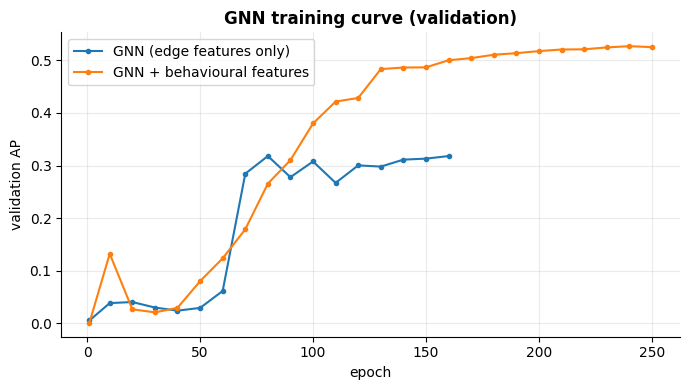

In [ ]:
GNN = {}
GNN['GNN (edge features only)']       = train_gnn(XE_A, 'GNN-A')
GNN['GNN + behavioural features']     = train_gnn(XE_B, 'GNN-B')
for k, v in GNN.items(): print(f"{k:30s} best val AP = {v['best_ap']:.4f}")
plt.figure(figsize=(7, 4))
for k, v in GNN.items():
    h_ = np.array(v['hist']); plt.plot(h_[:, 0], h_[:, 2], 'o-', ms=3, label=k)
plt.xlabel('epoch'); plt.ylabel('validation AP'); plt.title('GNN training curve (validation)'); plt.legend(); save_fig('fig01_gnn_training_curve')

## 🌲 Step 5 — XGBoost reference (same features, same split) for a fair comparison

In [ ]:
XGB_DEV = XGB_DEVICE
cfgs = [(10, 1, 1)] if QUICK_TEST else [(10, 1, 1), (10, 20, 5)]
res = []
for md_, spw, mcw in cfgs:
    m = xgb.XGBClassifier(n_estimators=60 if QUICK_TEST else 1500, learning_rate=0.05, max_depth=md_, min_child_weight=mcw, subsample=0.8,
                          colsample_bytree=0.8, reg_lambda=1.0, scale_pos_weight=spw, eval_metric='aucpr', early_stopping_rounds=100,
                          tree_method='hist', device=XGB_DEV, random_state=SEED, n_jobs=-1)
    m.fit(X_raw[:i_tr], y_tr, eval_set=[(X_raw[i_tr:i_va], y_va)], verbose=False)
    ap = average_precision_score(y_va, m.predict_proba(X_raw[i_tr:i_va])[:, 1]); res.append((ap, (md_, spw, mcw), m))
    print(f"XGBoost depth={md_} spw={spw} mcw={mcw} → val AP={ap:.4f}")
xgb_ap, xgb_cfg, xgb_model = max(res, key=lambda r: r[0])
xgb_va, xgb_te = xgb_model.predict_proba(X_raw[i_tr:i_va])[:, 1], xgb_model.predict_proba(X_raw[i_va:])[:, 1]
print("reference XGBoost config", xgb_cfg, "| val AP", round(xgb_ap, 4))

XGBoost depth=10 spw=1 mcw=1 → val AP=0.6313
XGBoost depth=10 spw=20 mcw=5 → val AP=0.6350
reference XGBoost config (10, 20, 5) | val AP 0.635


## 🔀 Step 6 — Blend (XGBoost + best GNN)
Weight chosen on **validation AP only** (grid 0 … 1). The GNN scores are out-of-sample for every row, so there is no stacking leakage.

In [ ]:
best_gnn = max(GNN, key=lambda k: GNN[k]['best_ap'])
ws = np.linspace(0, 1, 11); aps_w = [average_precision_score(y_va, w*xgb_va + (1-w)*GNN[best_gnn]['va']) for w in ws]
W = float(ws[int(np.argmax(aps_w))])
print(f"best GNN variant: {best_gnn} | blend weight on XGBoost = {W:.1f}  (val AP {max(aps_w):.4f})")
blend_va = W*xgb_va + (1-W)*GNN[best_gnn]['va']; blend_te = W*xgb_te + (1-W)*GNN[best_gnn]['te']

best GNN variant: GNN + behavioural features | blend weight on XGBoost = 0.7  (val AP 0.6428)


## 📈 Step 7 — Full metrics for EVERY model (threshold = best-F1 on validation; test touched once)

In [ ]:
def pick_threshold(y, s):
    p, r, t = precision_recall_curve(y, s); f = 2*p[:-1]*r[:-1]/(p[:-1]+r[:-1]+1e-12)
    return float(t[np.argmax(f)]), float(f.max())

def full_metrics(name, y, s, thr, probabilistic):
    pred = (s >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    k = int(y.sum()); topk = np.argsort(-s)[:k]
    return dict(Model=name, Threshold=thr,
             Accuracy=accuracy_score(y, pred), Balanced_Accuracy=balanced_accuracy_score(y, pred),
             Precision=precision_score(y, pred, zero_division=0), Recall=recall_score(y, pred),
             Specificity=tn/(tn+fp), F1=f1_score(y, pred), F2=fbeta_score(y, pred, beta=2),
             ROC_AUC=roc_auc_score(y, s), AP_PR_AUC=average_precision_score(y, s),
             MCC=matthews_corrcoef(y, pred), Cohen_Kappa=cohen_kappa_score(y, pred),
             FPR=fp/(fp+tn), FNR=fn/(fn+tp), Precision_at_k=float(y[topk].mean()),
             Brier=brier_score_loss(y, s) if probabilistic else np.nan,
             Log_Loss=log_loss(y, np.clip(s, 1e-7, 1-1e-7)) if probabilistic else np.nan,
             TP=int(tp), FP=int(fp), FN=int(fn), TN=int(tn), Alerts=int(tp+fp))

V = {'XGBoost (reference)': dict(va=xgb_va, te=xgb_te, prob=True)}
for k, v in GNN.items(): V[k] = dict(va=v['va'], te=v['te'], prob=True)
V[f'Blend (XGBoost + {best_gnn})'] = dict(va=blend_va, te=blend_te, prob=True)
for k, v in V.items():
    v['thr'], v['val_f1'] = pick_threshold(y_va, v['va']); v['pred'] = (v['te'] >= v['thr']).astype(int)
full = pd.DataFrame([full_metrics(k, y_te, v['te'], v['thr'], v['prob']) | {'Val_AP': average_precision_score(y_va, v['va']), 'Val_F1': v['val_f1']} for k, v in V.items()]).set_index('Model')
save_table(full, 'G03_all_metrics_all_models_TEST')
compact = full[['Accuracy','Balanced_Accuracy','Precision','Recall','Specificity','F1','F2','ROC_AUC','AP_PR_AUC','MCC','Cohen_Kappa','Brier','Log_Loss','Precision_at_k']]
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
print("TEST-SET METRICS (same held-out period):"); display(compact.round(4))
print("\nConfusion-matrix counts + alert volume:"); display(full[['Threshold','TP','FP','FN','TN','FPR','FNR','Alerts']].round(5))
FINAL = max(V, key=lambda k: full.loc[k, 'Val_AP'])           # chosen on VALIDATION AP only
print(f"\n🏆 headline model (best validation AP): {FINAL}")
print("⚠️ Accuracy is ~99.9 % even for a model that finds nothing — judge by AP, ROC-AUC, Precision, Recall, F1, MCC.")

TEST-SET METRICS (same held-out period):


,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,F2,ROC_AUC,AP_PR_AUC,MCC,Cohen_Kappa,Brier,Log_Loss,Precision_at_k
Model,,,,,,,,,,,,,,
XGBoost (reference),0.9992,0.8107,0.8950,0.6216,0.9999,0.7337,0.6620,0.9921,0.7406,0.7455,0.7333,0.0007,0.0038,0.6934
GNN (edge features only),0.9986,0.6974,0.6580,0.3951,0.9996,0.4937,0.4294,0.9702,0.4630,0.5092,0.4931,0.0091,0.0370,0.4886
GNN + behavioural features,0.9990,0.8220,0.7423,0.6444,0.9996,0.6899,0.6619,0.9930,0.6876,0.6911,0.6894,0.0097,0.0369,0.6678
Blend (XGBoost + GNN + behavioural features),0.9992,0.8099,0.9035,0.6199,0.9999,0.7353,0.6614,0.9932,0.7489,0.7480,0.7349,0.0015,0.0091,0.6973



Confusion-matrix counts + alert volume:


,Threshold,TP,FP,FN,TN,FPR,FNR,Alerts
Model,,,,,,,,
XGBoost (reference),0.59143,1117,131,680,1013741,0.00013,0.37841,1248
GNN (edge features only),0.81770,710,369,1087,1013503,0.00036,0.60490,1079
GNN + behavioural features,0.97720,1158,402,639,1013470,0.00040,0.35559,1560
Blend (XGBoost + GNN + behavioural features),0.71117,1114,119,683,1013753,0.00012,0.38008,1233



🏆 headline model (best validation AP): Blend (XGBoost + GNN + behavioural features)
⚠️ Accuracy is ~99.9 % even for a model that finds nothing — judge by AP, ROC-AUC, Precision, Recall, F1, MCC.


## 🔬 Step 7b — Does the threshold transfer? (score-shift check + rank-matched threshold)
The validation graph (train+val edges) is smaller than the test graph (all edges), so scores can drift. If the **alert rate** on test differs a lot from validation, use the label-free *rank-matched* threshold (flag the same **fraction** of transactions as on validation).

In [ ]:
shift = pd.DataFrame([{'Model': k, 'mean_score_normal_val': v['va'][y_va==0].mean(), 'mean_score_normal_test': v['te'][y_te==0].mean(),
                       'alert_rate_val': (v['va'] >= v['thr']).mean(), 'alert_rate_test': (v['te'] >= v['thr']).mean()} for k, v in V.items()]).set_index('Model')
display(shift.round(5)); save_table(shift, 'G03b_score_shift_check')
rm_rows = []
for k, v in V.items():
    q = (v['va'] >= v['thr']).mean(); thr2 = float(np.quantile(v['te'], 1 - q))          # label-free: same alert FRACTION as validation
    rm_rows.append(full_metrics(f'{k} [rank-matched threshold]', y_te, v['te'], thr2, v['prob']))
rm = pd.DataFrame(rm_rows).set_index('Model'); display(rm[['Threshold','Precision','Recall','F1','MCC','Alerts']].round(4)); save_table(rm, 'G03c_rank_matched_threshold_metrics')
print("Compare with the table above: if Precision/Recall/F1 differ a lot, the score scale shifted between validation and test — report both.")

,mean_score_normal_val,mean_score_normal_test,alert_rate_val,alert_rate_test
Model,,,,
XGBoost (reference),0.00047,0.00056,0.00063,0.00123
GNN (edge features only),0.02456,0.02786,0.00064,0.00106
GNN + behavioural features,0.02442,0.02241,0.00076,0.00154
Blend (XGBoost + GNN + behavioural features),0.00766,0.00712,0.00061,0.00121


,Threshold,Precision,Recall,F1,MCC,Alerts
Model,,,,,,
XGBoost (reference) [rank-matched threshold],0.9889,0.9844,0.3500,0.5164,0.5866,639
GNN (edge features only) [rank-matched threshold],0.8441,0.8126,0.2944,0.4322,0.4886,651
GNN + behavioural features [rank-matched threshold],0.9937,0.9148,0.3945,0.5513,0.6004,775
Blend (XGBoost + GNN + behavioural features) [rank-matched threshold],0.9893,0.9824,0.3417,0.5070,0.5790,625


Compare with the table above: if Precision/Recall/F1 differ a lot, the score scale shifted between validation and test — report both.


## 🧾 Step 8 — Classification reports

In [ ]:
rep_txt, rep_rows = [], []
for k, v in V.items():
    r = classification_report(y_te, v['pred'], target_names=['Normal','Fraud'], digits=4, zero_division=0)
    rep_txt.append(f"===== {k}   (threshold {v['thr']:.4f}) =====\n{r}")
    d = classification_report(y_te, v['pred'], target_names=['Normal','Fraud'], output_dict=True, zero_division=0)
    for cls in ['Normal','Fraud','macro avg','weighted avg']:
        rep_rows.append({'Model': k, 'Class': cls, **{a: d[cls][a] for a in ['precision','recall','f1-score','support']}})
    print(f"\n===== {k}   (threshold {v['thr']:.4f}) =====\n{r}")
open(f'{TAB}/classification_reports.txt', 'w').write("\n\n".join(rep_txt)); SAVED.append(f'{TAB}/classification_reports.txt')
save_table(pd.DataFrame(rep_rows), 'G04_classification_reports_all_models', index=False)


===== XGBoost (reference)   (threshold 0.5914) =====
              precision    recall  f1-score   support

      Normal     0.9993    0.9999    0.9996   1013872
       Fraud     0.8950    0.6216    0.7337      1797

    accuracy                         0.9992   1015669
   macro avg     0.9472    0.8107    0.8666   1015669
weighted avg     0.9991    0.9992    0.9991   1015669


===== GNN (edge features only)   (threshold 0.8177) =====
              precision    recall  f1-score   support

      Normal     0.9989    0.9996    0.9993   1013872
       Fraud     0.6580    0.3951    0.4937      1797

    accuracy                         0.9986   1015669
   macro avg     0.8285    0.6974    0.7465   1015669
weighted avg     0.9983    0.9986    0.9984   1015669


===== GNN + behavioural features   (threshold 0.9772) =====
              precision    recall  f1-score   support

      Normal     0.9994    0.9996    0.9995   1013872
       Fraud     0.7423    0.6444    0.6899      1797

    accu

## 🎲 Step 9 — Bootstrap 95 % confidence intervals + paired comparison vs XGBoost

In [ ]:
rng = np.random.default_rng(0); pos = np.where(y_te==1)[0]; neg = np.where(y_te==0)[0]
NNEG = min(200_000, len(neg)); NB = 10 if QUICK_TEST else 100; BS_ = {k: {'AP': [], 'F1': [], 'ROC_AUC': []} for k in V}
for _ in range(NB):
    b = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, NNEG, replace=False)])
    w = np.where(y_te[b]==1, 1.0, len(neg)/NNEG)
    for k, v in V.items():
        BS_[k]['AP'].append(average_precision_score(y_te[b], v['te'][b], sample_weight=w))
        BS_[k]['F1'].append(f1_score(y_te[b], v['pred'][b], sample_weight=w))
        BS_[k]['ROC_AUC'].append(roc_auc_score(y_te[b], v['te'][b], sample_weight=w))
ci = pd.DataFrame({k: {f'{m}_{q}': np.percentile(BS_[k][m], p) for m in ['AP','F1','ROC_AUC'] for q, p in [('lo',2.5),('mean',50),('hi',97.5)]} for k in V}).T
display(ci.round(4)); save_table(ci, 'G05_bootstrap_95CI')
for k in V:
    if k == 'XGBoost (reference)': continue
    d_ = np.array(BS_[k]['AP']) - np.array(BS_['XGBoost (reference)']['AP'])
    lo_, hi_ = np.percentile(d_, 2.5), np.percentile(d_, 97.5)
    print(f"Paired ΔAP ({k} − XGBoost): median {np.median(d_):+.4f}  95% CI [{lo_:+.4f}, {hi_:+.4f}] → "
          + ("significantly BETTER" if lo_ > 0 else "significantly WORSE" if hi_ < 0 else "no significant difference"))

,AP_lo,AP_mean,AP_hi,F1_lo,F1_mean,F1_hi,ROC_AUC_lo,ROC_AUC_mean,ROC_AUC_hi
XGBoost (reference),0.7241,0.7413,0.7648,0.7191,0.7333,0.7541,0.9908,0.9921,0.9932
GNN (edge features only),0.4374,0.4627,0.4949,0.4762,0.4948,0.5162,0.9657,0.9705,0.9738
GNN + behavioural features,0.6621,0.6882,0.7211,0.6680,0.6912,0.7092,0.9919,0.9930,0.9941
Blend (XGBoost + GNN + behavioural features),0.7331,0.7501,0.7722,0.7192,0.7349,0.7546,0.9922,0.9932,0.9943


Paired ΔAP (GNN (edge features only) − XGBoost): median -0.2788  95% CI [-0.3061, -0.2494] → significantly WORSE
Paired ΔAP (GNN + behavioural features − XGBoost): median -0.0529  95% CI [-0.0779, -0.0314] → significantly WORSE
Paired ΔAP (Blend (XGBoost + GNN + behavioural features) − XGBoost): median +0.0082  95% CI [+0.0057, +0.0118] → significantly BETTER


## 🖼️ Step 10 — Figures

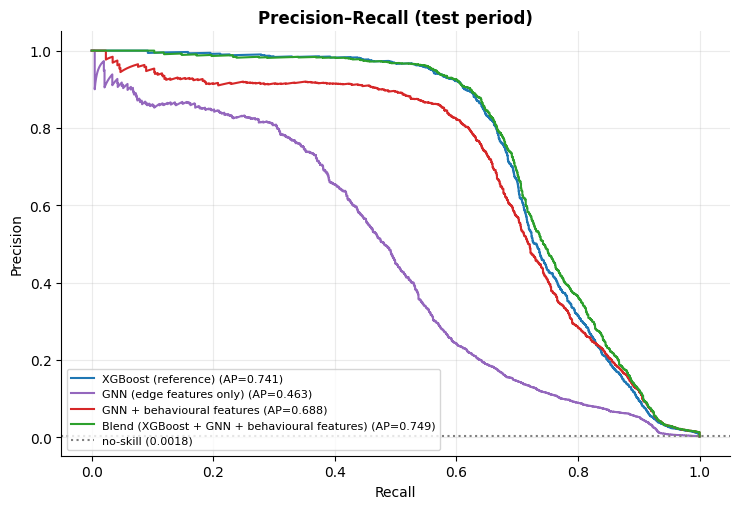

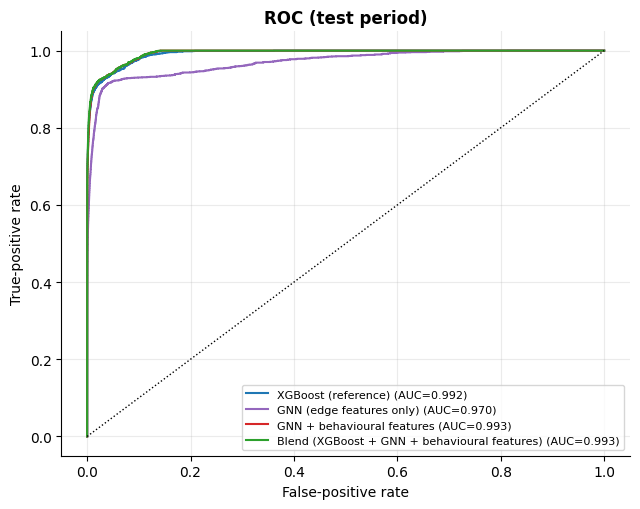

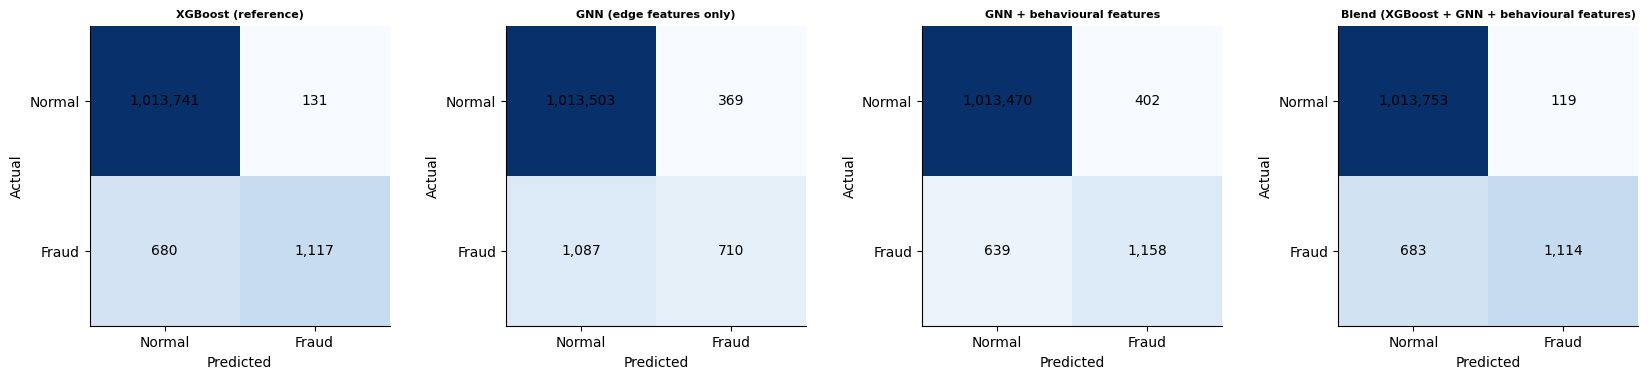

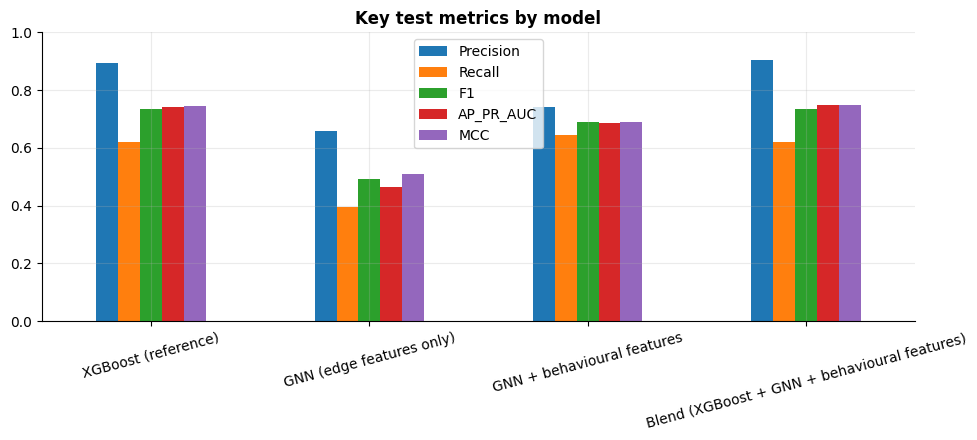

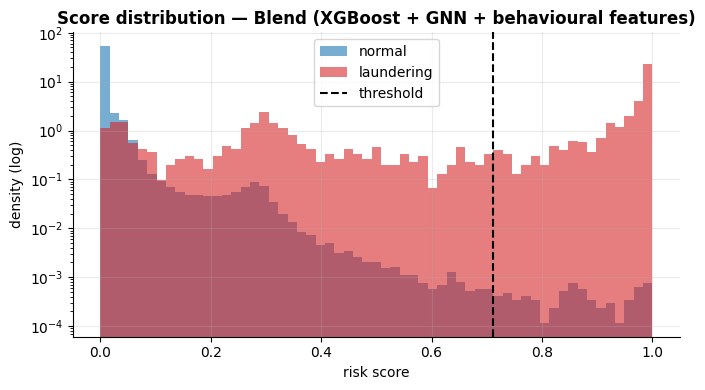

In [ ]:
COL = dict(zip(V, ['#1f77b4', '#9467bd', '#d62728', '#2ca02c']))
plt.figure(figsize=(7.5, 5.2))
for k, v in V.items():
    p_, r_, _ = precision_recall_curve(y_te, v['te']); plt.plot(r_, p_, color=COL[k], label=f"{k} (AP={average_precision_score(y_te, v['te']):.3f})")
plt.axhline(y_te.mean(), color='gray', ls=':', label=f'no-skill ({y_te.mean():.4f})'); plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision–Recall (test period)'); plt.legend(fontsize=8); save_fig('fig02_precision_recall')

plt.figure(figsize=(6.5, 5.2))
for k, v in V.items():
    f_, t_, _ = roc_curve(y_te, v['te']); plt.plot(f_, t_, color=COL[k], label=f"{k} (AUC={roc_auc_score(y_te, v['te']):.3f})")
plt.plot([0, 1], [0, 1], 'k:', lw=1); plt.xlabel('False-positive rate'); plt.ylabel('True-positive rate'); plt.title('ROC (test period)'); plt.legend(fontsize=8); save_fig('fig03_roc')

fig, axs = plt.subplots(1, len(V), figsize=(4.2*len(V), 3.8))
for ax, (k, v) in zip(np.atleast_1d(axs), V.items()):
    cm = confusion_matrix(y_te, v['pred'], labels=[0, 1]); ax.imshow(np.log10(cm + 1), cmap='Blues'); ax.grid(False)
    for i in range(2):
        for j in range(2): ax.text(j, i, f"{cm[i,j]:,}", ha='center', va='center', fontsize=10, color='black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Normal', 'Fraud']); ax.set_yticks([0, 1]); ax.set_yticklabels(['Normal', 'Fraud']); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(k, fontsize=8)
save_fig('fig04_confusion_matrices')

met = full[['Precision', 'Recall', 'F1', 'AP_PR_AUC', 'MCC']]; ax = met.plot.bar(figsize=(10, 4.5), rot=15); ax.set_ylim(0, 1); ax.set_title('Key test metrics by model'); ax.set_xlabel('')
save_fig('fig05_metric_bars')

sf = V[FINAL]['te']; plt.figure(figsize=(7, 4)); bins = np.linspace(0, 1, 60)
plt.hist(sf[y_te==0], bins=bins, alpha=.6, density=True, label='normal'); plt.hist(sf[y_te==1], bins=bins, alpha=.6, density=True, color='#d62728', label='laundering')
plt.yscale('log'); plt.axvline(V[FINAL]['thr'], color='k', ls='--', label='threshold'); plt.xlabel('risk score'); plt.ylabel('density (log)'); plt.title(f'Score distribution — {FINAL}'); plt.legend(); save_fig('fig06_score_distribution')

## 💾 Step 11 — Save everything (models, tables, figures, summary) + zip + Drive copy

In [ ]:
# =====================  SEPARATE GNN MODEL PACKAGE  =====================
GDIR = f'{ROOT}/saved_models_gnn'; os.makedirs(GDIR, exist_ok=True)
best_net = GNN[best_gnn]['net']; best_key = 'A_edge' if 'only' in best_gnn else 'B_behav'
for k, v in GNN.items(): torch.save(v['net'].state_dict(), f"{GDIR}/gnn_{'A_edge' if 'only' in k else 'B_behav'}.pt")
torch.save(best_net.state_dict(), f'{GDIR}/gnn_best.pt')
d_in_best = int(XE_A.shape[1] if best_key == 'A_edge' else XE_B.shape[1])
cfg = dict(best_variant=best_gnn, best_key=best_key, d_in=d_in_best, n_nodes=int(N_NODES), hidden=HIDDEN, layers=LAYERS, dropout=DROP,
           num_cols=num_cols, basic_cols=BASIC, cat_cols=cat_cols, onehot_dims=OH_DIMS, feature_order='[scaled numeric cols (A: BASIC only, B: all num_cols)] + [one-hot of cat_cols]',
           split='time 60/20/20', graph_mode='batch / whole-period graph (reverse edges + direction flag, mean aggregation, LayerNorm)')
json.dump(cfg, open(f'{GDIR}/gnn_config.json', 'w'), indent=2)
joblib.dump({'med': E_MED, 'mu': E_MU, 'sd': E_SD, 'num_cols': num_cols, 'basic': BASIC, 'cat_cols': cat_cols, 'feature_cols': feature_cols}, f'{GDIR}/gnn_edge_scaler.pkl')
pd.Series(ACC_UNIQ, name='account').to_csv(f'{GDIR}/account_index.csv', index_label='node_id')          # node id -> account string
xgb_model.save_model(f'{GDIR}/xgboost_reference.json')
for k, v in GNN.items(): np.save(f"{GDIR}/test_scores_{'A' if 'only' in k else 'B'}.npy", v['te'])
np.save(f'{GDIR}/test_scores_xgb.npy', xgb_te)

# stand-alone model definition (same architecture as above) so the GNN can be re-loaded WITHOUT this notebook
open(f'{GDIR}/gnn_model_def.py', 'w').write(r"""import torch, torch.nn as nn, torch.nn.functional as F_
CHUNK = 1_500_000
class Net(nn.Module):
    def __init__(s, d_in, n_nodes, hid, L, drop=0.0):
        super().__init__()
        s.N, s.L, s.drop = n_nodes, L, drop
        s.edge_proj = nn.Linear(d_in, hid); s.flag = nn.Parameter(torch.zeros(2, hid)); s.node0 = nn.Parameter(torch.randn(hid) * 0.1)
        s.lin_e = nn.ModuleList([nn.Linear(hid, hid) for _ in range(L)])
        s.mlps  = nn.ModuleList([nn.Sequential(nn.Linear(hid, hid), nn.ReLU(), nn.Linear(hid, hid)) for _ in range(L)])
        s.norms = nn.ModuleList([nn.LayerNorm(hid) for _ in range(L)])
        s.eps   = nn.Parameter(torch.zeros(L))
        s.head  = nn.Sequential(nn.Linear(3 * hid, hid), nn.ReLU(), nn.Dropout(drop), nn.Linear(hid, 1))
    def layer(s, l, h, E, src2, dst2, deg):
        agg = torch.zeros_like(h)
        for a in range(0, src2.shape[0], CHUNK):
            b = min(a + CHUNK, src2.shape[0])
            msg = F_.relu(h[src2[a:b]] + s.lin_e[l](E[a:b])); agg = agg.index_add(0, dst2[a:b], msg)
        agg = agg / deg[:, None]
        return s.norms[l](s.mlps[l]((1 + s.eps[l]) * h + agg))
    def encode(s, X, g):
        e = F_.relu(s.edge_proj(X)); E = torch.cat([e + s.flag[0], e + s.flag[1]], 0); h = s.node0[None, :].expand(s.N, -1).contiguous()
        for l in range(s.L):
            h = h + F_.dropout(F_.relu(s.layer(l, h, E, g['src2'], g['dst2'], g['deg'])), s.drop, s.training)
        return h, e
    def score(s, h, e, g, idx):
        return s.head(torch.cat([h[g['src'][idx]], h[g['dst'][idx]], e[idx]], 1)).squeeze(-1)

def make_graph(src, dst, n_nodes, device):
    src = torch.as_tensor(src, dtype=torch.long, device=device); dst = torch.as_tensor(dst, dtype=torch.long, device=device)
    src2 = torch.cat([src, dst]); dst2 = torch.cat([dst, src]); deg = torch.bincount(dst2, minlength=n_nodes).float().clamp(min=1.0)
    return dict(src=src, dst=dst, src2=src2, dst2=dst2, deg=deg)

@torch.no_grad()
def load_and_score(weights_path, cfg, X_edges, src, dst, device='cpu'):
    # X_edges: edge-feature matrix built exactly as in the notebook; src/dst: integer node ids (see account_index.csv). Returns a risk score per edge.
    net = Net(cfg['d_in'], cfg['n_nodes'], cfg['hidden'], cfg['layers']).to(device); net.load_state_dict(torch.load(weights_path, map_location=device)); net.eval()
    g = make_graph(src, dst, cfg['n_nodes'], device); h, e = net.encode(torch.as_tensor(X_edges, dtype=torch.float32, device=device), g)
    return torch.sigmoid(net.score(h, e, g, torch.arange(len(src), device=device))).cpu().numpy()
""")

# ---- RELOAD TEST: the stand-alone file must reproduce the notebook's own test scores ----
import importlib.util, sys
spec = importlib.util.spec_from_file_location('gnn_model_def', f'{GDIR}/gnn_model_def.py'); gm = importlib.util.module_from_spec(spec); spec.loader.exec_module(gm)
XE_best = XE_A if best_key == 'A_edge' else XE_B
sc_reload = gm.load_and_score(f'{GDIR}/gnn_best.pt', cfg, XE_best, src_np, dst_np, device=DEV)[i_va:]
dmax = float(np.abs(sc_reload - GNN[best_gnn]['te']).max())
print(f"RELOAD TEST: stand-alone gnn_model_def.py vs notebook scores → max abs difference = {dmax:.2e}", "✅" if dmax < 1e-4 else "❌ MISMATCH")
assert dmax < 1e-3

# ---- exports for the DeepGuard app (Cytoscape graph) ----
sc_gnn = GNN[best_gnn]['te']; thr_g = V[best_gnn]['thr']
te_src, te_dst = src_np[i_va:], dst_np[i_va:]
long = pd.DataFrame({'node': np.concatenate([te_src, te_dst]), 'score': np.concatenate([sc_gnn, sc_gnn]), 'fraud': np.concatenate([y_te, y_te])})
acc = long.groupby('node').agg(n_tx=('score', 'size'), max_risk=('score', 'max'), mean_risk=('score', 'mean'), n_flagged=('score', lambda s: int((s >= thr_g).sum())), fraud_tx_in_test=('fraud', 'sum')).reset_index()
acc.insert(0, 'account', ACC_UNIQ[acc['node'].to_numpy()]); acc = acc.drop(columns='node').sort_values('max_risk', ascending=False)
acc.to_csv(f'{GDIR}/gnn_account_risk.csv', index=False)
top = np.argsort(-sc_gnn)[:200]
node_risk = acc.set_index('account')['max_risk'].to_dict(); nodes = {}; edges = []
for r, j in enumerate(top):
    a, b = ACC_UNIQ[te_src[j]], ACC_UNIQ[te_dst[j]]
    for x in (a, b): nodes[x] = {'data': {'id': x, 'risk': float(node_risk.get(x, 0.0))}}
    edges.append({'data': {'id': f'e{r}', 'source': a, 'target': b, 'score': float(sc_gnn[j]), 'amount': float(TX['Amount_Paid'].iloc[j]),
                           'format': str(TX['Payment_Format'].iloc[j]), 'time': str(TX['Timestamp'].iloc[j]), 'flagged': bool(sc_gnn[j] >= thr_g)}})
json.dump({'nodes': list(nodes.values()), 'edges': edges, 'model': best_gnn, 'threshold': float(thr_g)}, open(f'{GDIR}/cytoscape_top_alerts.json', 'w'))
print(f"exported {len(acc):,} account scores and a {len(nodes)}-node / {len(edges)}-edge Cytoscape graph")

# ---- metadata + README + zip + Drive ----
meta = dict(split='time-based 60/20/20', graphs='train-period / train+val / all edges', headline_model=FINAL, best_gnn=best_gnn, blend_weight_xgb=W,
            hidden=HIDDEN, layers=LAYERS, steps=EPOCHS, reload_test_max_diff=dmax,
            test_metrics={k: {m: float(full.loc[k, m]) for m in ['Accuracy','Precision','Recall','F1','ROC_AUC','AP_PR_AUC','MCC']} for k in V},
            note='GNN scores a batch using the whole period graph (structure only, never labels); XGBoost features are strictly past-only. GNN is an optional network-analysis module.')
json.dump(meta, open(f'{OUT}/summary.json', 'w'), indent=2); shutil.copy(f'{OUT}/summary.json', f'{GDIR}/summary.json'); SAVED.append(f'{OUT}/summary.json')
open(f'{GDIR}/README_GNN.md', 'w').write(f"""# DeepGuard GNN module (separate from the core detector)
Best GNN variant: **{best_gnn}** | headline model by validation AP: **{FINAL}**
Files: gnn_best.pt (+ gnn_A_edge.pt, gnn_B_behav.pt) · gnn_config.json · gnn_edge_scaler.pkl · account_index.csv · gnn_model_def.py · xgboost_reference.json
App exports: gnn_account_risk.csv (risk per account) · cytoscape_top_alerts.json (Cytoscape.js elements)
Reload: `import gnn_model_def as gm; gm.load_and_score('gnn_best.pt', json.load(open('gnn_config.json')), X_edges, src, dst)`
Mode: batch / period graph (not real-time). Core models live in saved_models_v4 / training_results_final.
""")
shutil.copytree(GDIR, f'{OUT}/models', dirs_exist_ok=True)
zpath = f'{ROOT}/deepguard_gnn_results.zip'
with zipfile.ZipFile(zpath, 'w', zipfile.ZIP_DEFLATED) as z:
    for root_, _, fs in os.walk(OUT):
        for f_ in fs: z.write(os.path.join(root_, f_), os.path.relpath(os.path.join(root_, f_), OUT))
try:
    from google.colab import drive; drive.mount('/content/drive')
    shutil.copytree(GDIR, '/content/drive/MyDrive/DeepGuard/saved_models_gnn', dirs_exist_ok=True)
    shutil.copytree(OUT, '/content/drive/MyDrive/DeepGuard/gnn_results', dirs_exist_ok=True)
    print('✅ copied to Drive → MyDrive/DeepGuard/saved_models_gnn  and  gnn_results')
except Exception as e: print('Drive copy skipped:', e)
print('✅ GNN model package:', GDIR, '\n✅ results folder:', OUT, '| zip:', zpath); print(sorted(os.listdir(GDIR)))
try:
    from google.colab import files; files.download(zpath)
except Exception: pass

RELOAD TEST: stand-alone gnn_model_def.py vs notebook scores → max abs difference = 3.58e-07 ✅
exported 356,395 account scores and a 250-node / 200-edge Cytoscape graph
Mounted at /content/drive
✅ copied to Drive → MyDrive/DeepGuard/saved_models_gnn  and  gnn_results
✅ GNN model package: /content/saved_models_gnn 
✅ results folder: /content/deepguard_gnn_results | zip: /content/deepguard_gnn_results.zip
['README_GNN.md', '__pycache__', 'account_index.csv', 'cytoscape_top_alerts.json', 'gnn_A_edge.pt', 'gnn_B_behav.pt', 'gnn_account_risk.csv', 'gnn_best.pt', 'gnn_config.json', 'gnn_edge_scaler.pkl', 'gnn_model_def.py', 'summary.json', 'test_scores_A.npy', 'test_scores_B.npy', 'test_scores_xgb.npy', 'xgboost_reference.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>